### Desafio 1 - Deteccion temprana de renuncias en empresas de telecomunicaciones

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G83

#### Descripción

La oferta de servicios de telefonía ha ido en aumento en los últimos años, provocando una alta competencia que se traduce en menores precios y mejores prestaciones. Sin embargo, estas empresas luchan día a día por retener a sus clientes ya que el costo de un nuevo cliente es mayor que el de retener a un cliente antiguo. 

El objetivo de este desafío es entrenar un modelo de ensamble que permita predecir tempranamente si un cliente renunciará a la compañía, además de poder explicar cuál o cuáles son las características que más incidencia tienen en la separación de clientes con y sin renuncia. Para esto deberás aplicar los conceptos y herramientas aprendidas hasta ahora.

La muestra con la que se trabajará es un archivo llamado `telecom_churn.csv`, que contiene los siguientes atributos asociados a clientes:

1.	Churn (Variable objetivo): valor 1 si el cliente canceló el servicio, 0 si no 
2.	AccountWeeks: número de semanas que el cliente ha tenido activa la cuenta 
3.	ContractRenewal: toma el valor 1 si el cliente ha renovado recientemente el contrato, 0 en caso contrario 
4.	DataPlan: valor 1 si el cliente tiene plan de datos, 0 en caso contrario 
5.	DataUsage: Gigabytes de uso mensual de datos 
6.	CustServCalls: número de llamadas al servicio de atención al cliente 
7.	DayMins: promedio de minutos diurnos al mes 
8.	DayCalls: número medio de llamadas diurnas 
9.	MonthlyCharge: factura mensual media 
10.	OverageFee: mayor cuota de exceso en los últimos 12 meses 
11.	RoamMin: minutos de Roaming e Roaming e Roaming Roaming


Para lograr lo solicitado, debes realizar las siguientes tareas:

#### Pregunta 1

1. Importa las librerías necesarias y la base de datos, y realiza un análisis por variable usando visualizaciones. Debes considerar las posibles correlaciones y representarlas en un heatmap.

In [264]:
# Importar las bibliotecas necesarias

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [451]:
# Importamos las librerias necesarias para realizar el problema 4

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [472]:
# Importamos la libreria para hacer desarrollar el ROC y AUC donde se requiera en los problemas

from sklearn.metrics import roc_curve, roc_auc_score

In [266]:
# Importamos la base de datos
df = pd.read_csv('telecom_churn.csv')

In [268]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [270]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB


In [272]:
# Para hallar si hay valores nulos en los datos
df.isna().sum()

Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

Podemos ver que no hay valores nulos en los datos

Procedemos a hacer un analisis por variable usando visualizaciones

In [274]:
df.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

In [276]:
len(df.columns)

11

In [278]:
def representacion_de_las_variables(df):
    plt.figure(figsize = (13, 9))

    for idx, col in enumerate(df.columns):
        
        # La numeracion de los subplot comienza 1, por lo que se usa idx+1.
        # idx+1 ademas te va indicar en que columna estas
        plt.subplot(4, 3, idx+1)
        plt.title(col)
        plt.xlabel('')

        if len(df[col].unique()) > 2:
            sns.histplot(x=col, kde = True, data=df)

        else:
            sns.countplot(y=df[col], hue=df[col], palette='viridis', dodge=False)

        plt.tight_layout()

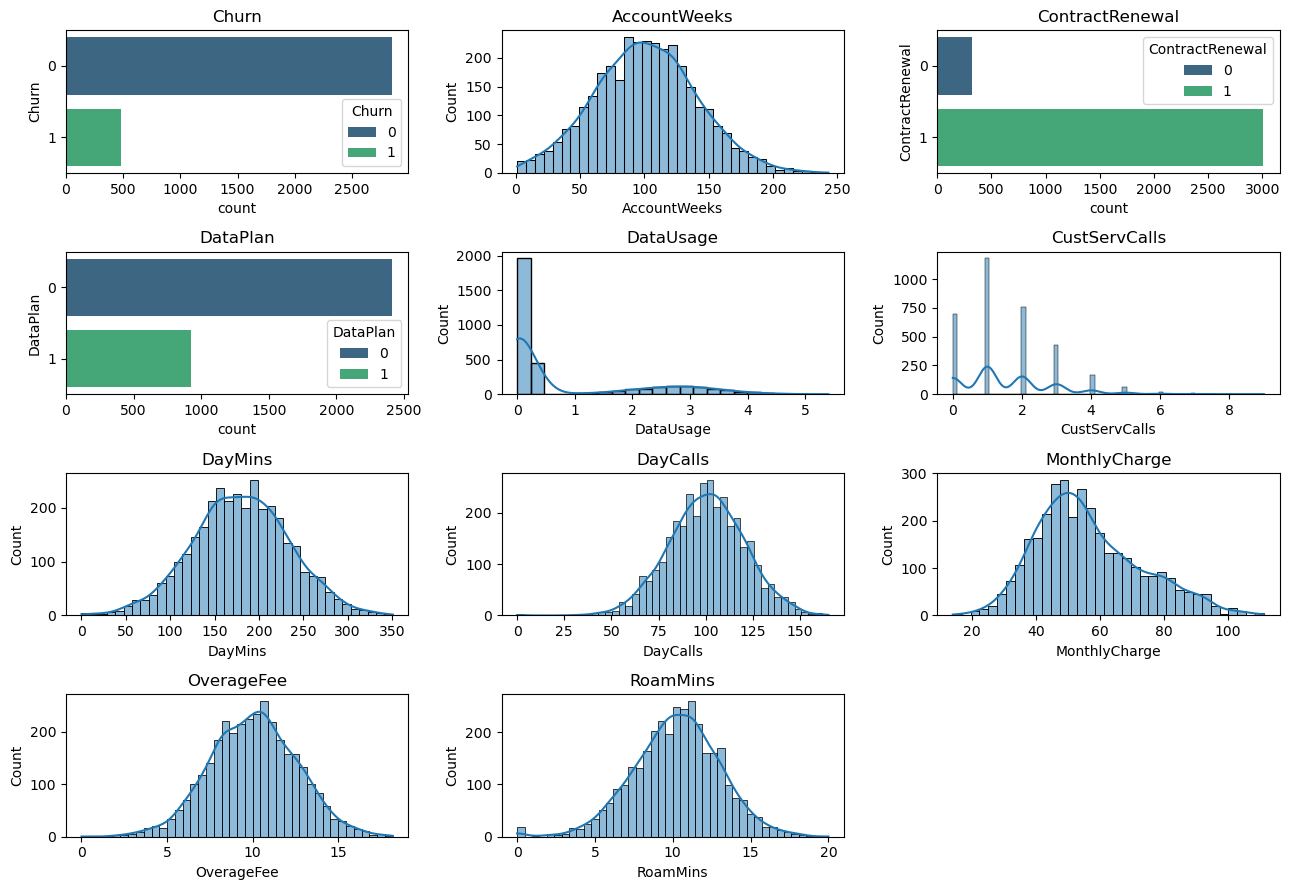

In [37]:
representacion_de_las_variables(df)

Vemos que hay 3 variables binarias:
- Churn
- ContractRenewal
- DataPlan

Vemos que hay 8 variables continuas:
- AccountWeeks
- DataUsage
- CustServCalls
- DayMins
- DayCalls
- MonthlyCharge
- OverageFee
- RoamMins

In [280]:
df.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

In [282]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


In [284]:
df['DataUsage'].value_counts()

DataUsage
0.00    1813
0.31      41
0.21      39
0.29      36
0.26      34
        ... 
5.40       1
4.40       1
4.73       1
4.64       1
0.68       1
Name: count, Length: 174, dtype: int64

In [286]:
df['CustServCalls'].value_counts()

CustServCalls
1    1181
2     759
0     697
3     429
4     166
5      66
6      22
7       9
9       2
8       2
Name: count, dtype: int64

#### Procedemos a ver ahora los outliers del conjunto de datos

Usamos una funcion para graficar los outliers de las variables continuas

In [288]:
# Funcion para revisar los outliers

def plot_boxplot_with_outliers(data, column_name, outlier_color = 'red', factor = 1.5):
    # Calcular los estadísticos clave
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calcular los límites para los valores atípicos
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    
    # Crear un gráfico de diagrama de caja (boxplot)
    plt.figure(figsize=(8,10))
    sns.boxplot(y=data[column_name], showfliers=False)

    # plt.title(f'Diagrama de Caja de {column_name}')
    plt.ylabel(column_name)
    plt.xlabel(i)
    
    # Resaltar los valores atípicos en un color diferente
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    plt.scatter(y=outliers[column_name], x=[0]*len(outliers), color=outlier_color, label='Outliers')

    # Anotar los valores de límites y cuartiles en el gráfico
    plt.text(0.35, Q1-0.55, f'Q1: {Q1:.2f}', fontsize=10)
    plt.text(0.35, Q3+0.3, f'Q3: {Q3:.2f}', fontsize=10)
    plt.text(0.205, lower_bound, f'Límite Inferior: {lower_bound:.2f}',fontsize=10)
    plt.text(0.205, upper_bound, f'Límite Superior: {upper_bound:.2f}',fontsize=10)
    plt.legend()
    plt.show()
    
    return outliers

#### Revisamos en primera instancia los outliers de las variables continuas

Recordar que habiamos determinado previamente cuales eran las variables continuas, siendo estas 8:
- AccountWeeks
- DataUsage
- CustServCalls
- DayMins
- DayCalls
- MonthlyCharge
- OverageFee
- RoamMins

In [290]:
df_var_cont = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']]
df_var_cont

,AccountWeeks,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,128,2.70,1,265.1,110,89.0,9.87,10.0
1,107,3.70,1,161.6,123,82.0,9.78,13.7
2,137,0.00,0,243.4,114,52.0,6.06,12.2
3,84,0.00,2,299.4,71,57.0,3.10,6.6
4,75,0.00,3,166.7,113,41.0,7.42,10.1
...,...,...,...,...,...,...,...,...
3328,192,2.67,2,156.2,77,71.7,10.78,9.9
3329,68,0.34,3,231.1,57,56.4,7.67,9.6
3330,28,0.00,2,180.8,109,56.0,14.44,14.1
3331,184,0.00,2,213.8,105,50.0,7.98,5.0


<Figure size 200x100 with 0 Axes>

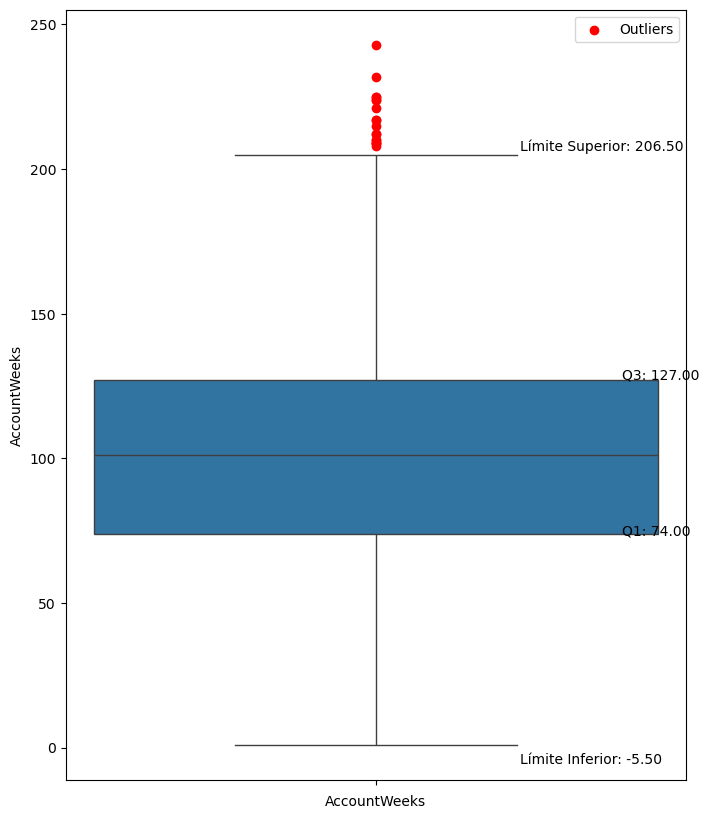

<Figure size 200x100 with 0 Axes>

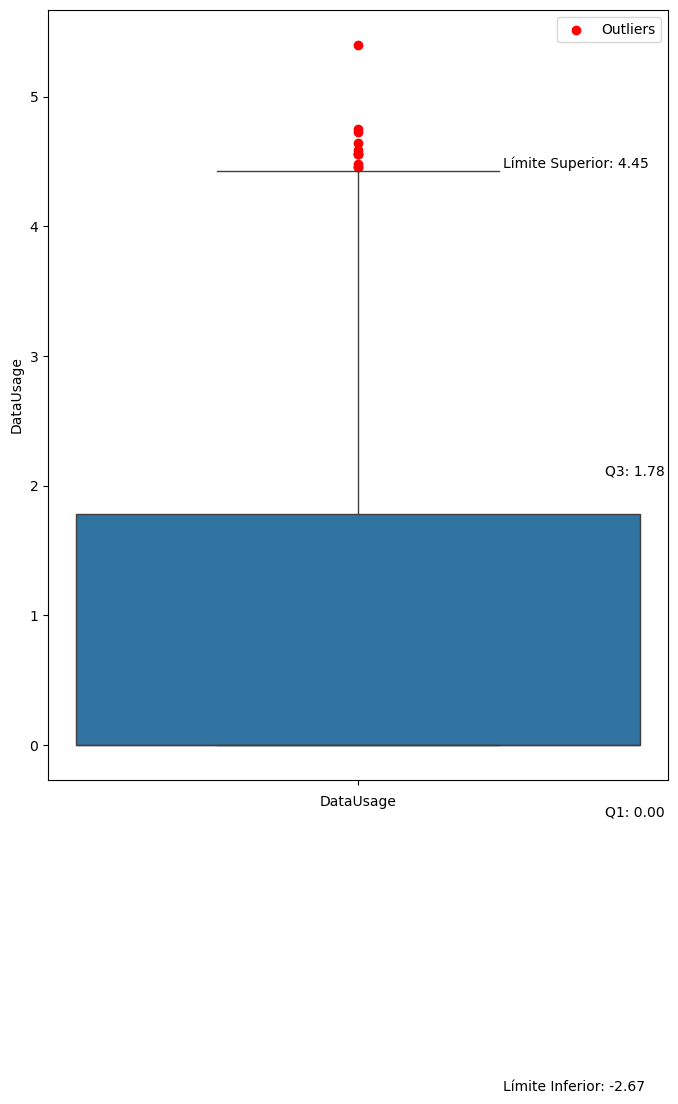

<Figure size 200x100 with 0 Axes>

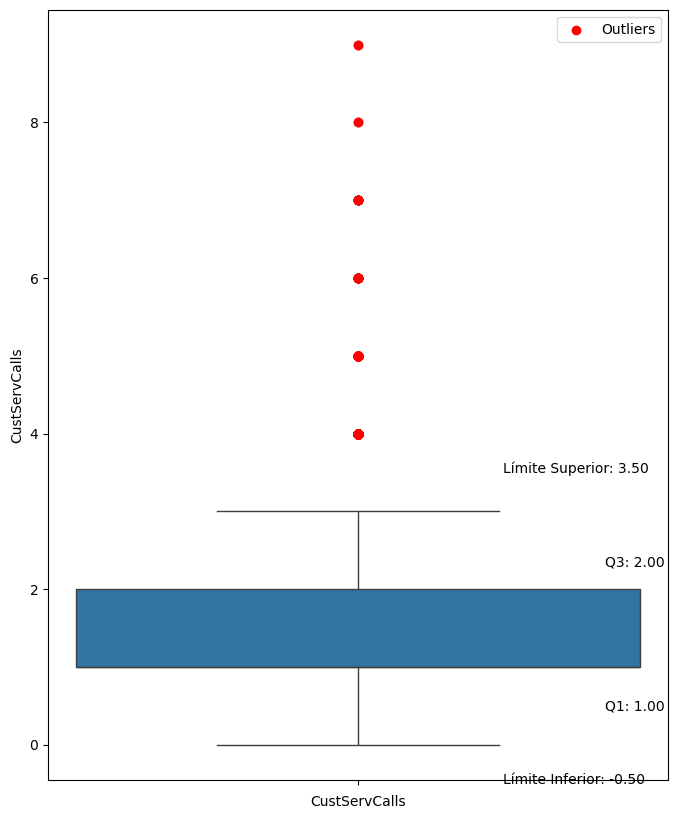

<Figure size 200x100 with 0 Axes>

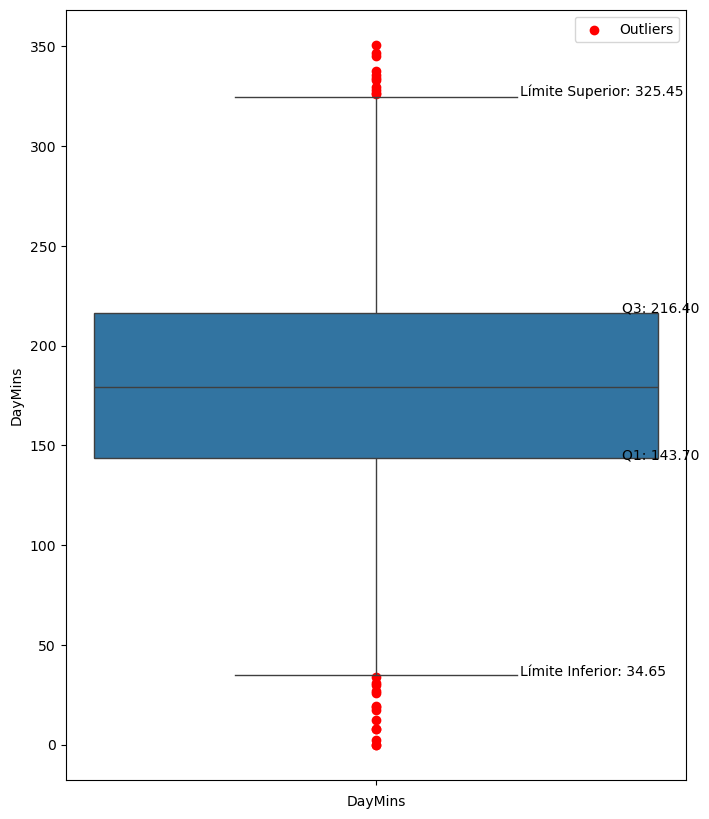

<Figure size 200x100 with 0 Axes>

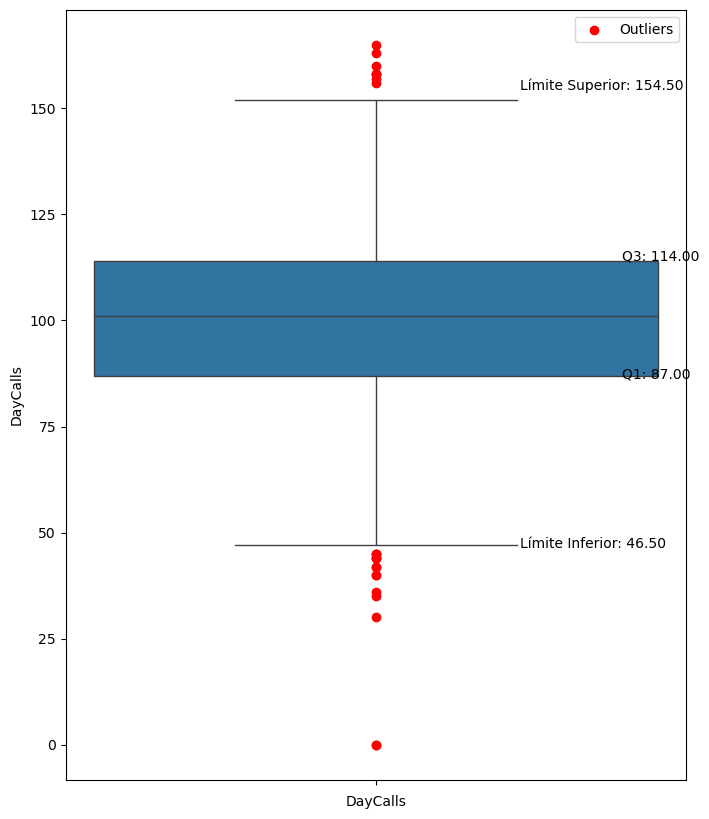

<Figure size 200x100 with 0 Axes>

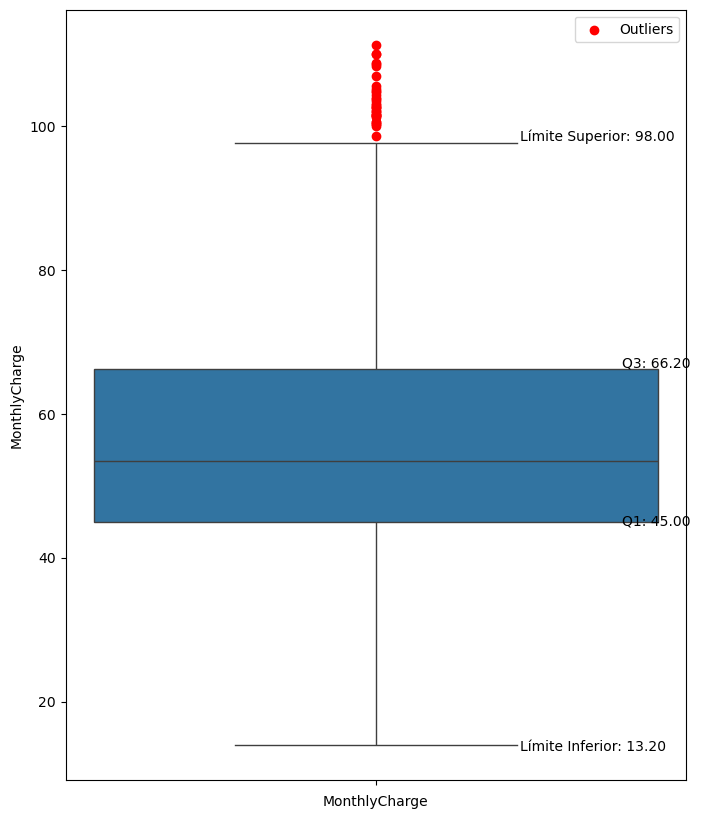

<Figure size 200x100 with 0 Axes>

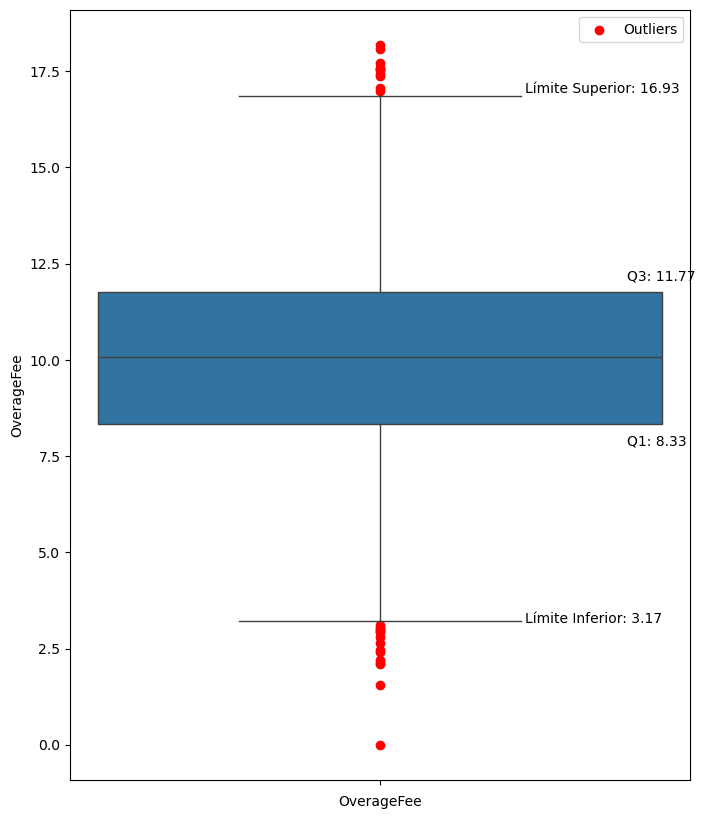

<Figure size 200x100 with 0 Axes>

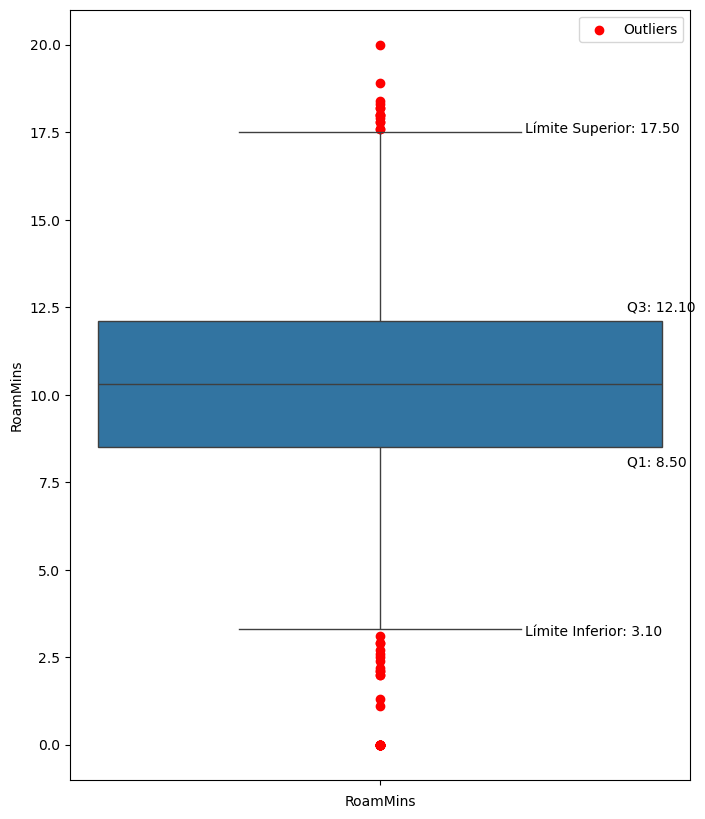

In [292]:
# Revision de los outliers de las variables continuas

for i in df_var_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df, column_name = i, outlier_color = 'red', factor = 1.5)

In [294]:
Q1 = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']].quantile(0.25)
Q3 = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']].quantile(0.75)
IQR = Q3 - Q1
# Recuento de outliers como recuento
((df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] < (Q1 - 1.5 * IQR)) | (df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] > (Q3 + 1.5 * IQR))).sum()

AccountWeeks      18
DataUsage         11
CustServCalls    267
DayMins           25
DayCalls          23
MonthlyCharge     34
OverageFee        24
RoamMins          46
dtype: int64

In [296]:
# Recuento de outliers como %
((df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] < (Q1 - 1.5 * IQR)) | (df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] > (Q3 + 1.5 * IQR))).mean()

AccountWeeks     0.005401
DataUsage        0.003300
CustServCalls    0.080108
DayMins          0.007501
DayCalls         0.006901
MonthlyCharge    0.010201
OverageFee       0.007201
RoamMins         0.013801
dtype: float64

Vemos que solamente la variable CustServCalls tiene un % considerado de datos outliers.

#### Revisamos en segunda instancias la distribución de los datos de las variables binarias (variable categóricas)

Recordar que habiamos determinado previamente cuales eran las variables binarias (variables categóricas), siendo estas 3:

- Churn
- ContractRenewal
- DataPlan

In [298]:
df['Churn'].value_counts(dropna = False)

Churn
0    2850
1     483
Name: count, dtype: int64

In [300]:
df['ContractRenewal'].value_counts(dropna = False)

ContractRenewal
1    3010
0     323
Name: count, dtype: int64

In [302]:
df['DataPlan'].value_counts(dropna = False)

DataPlan
0    2411
1     922
Name: count, dtype: int64

Realizamos una copia del dataframe

In [304]:
df2 = df.copy()

In [306]:
df2.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


##### Revisamos las posibles correlaciones de las variables, incluido con la variable objetivo 'Churn'

##### Correlaciones entre las variables categóricas con la variable objetivo ('Churn')

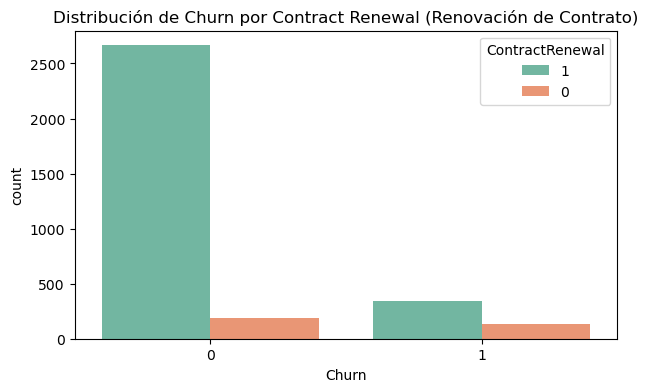

In [312]:
df2['Churn'] = df2['Churn'].astype(str)
df2['ContractRenewal'] = df2['ContractRenewal'].astype(str)

plt.figure(figsize=(7, 4))  # Ajustar el tamaño de la figura
sns.countplot(x='Churn', hue='ContractRenewal', data=df2, palette='Set2')
plt.title('Distribución de Churn por Contract Renewal (Renovación de Contrato)')
plt.show()

- Podemos ver una gran cantidad de clientes que no han cancelado el servicio y que además han renovado, lo cual es muy bueno. Y que son muy pocos los clientes que no han cancelado el servicio y que no han renovado. (Churn = 0)
- Por otro lado, podemos que los clientes que han cancelado el servicio, también han renovado, y que son muy pocos los clientes que han cancelado el servicio y no han renovado.

Esto es muy bueno, lo cual indica que los clientes son fieles al servicio de telefonía y el servicio de telefonía está brindando un buen servicio, buenas promociones entre otros para retener a sus clientes.

In [317]:
df['Churn'].value_counts(dropna = False)

Churn
0    2850
1     483
Name: count, dtype: int64

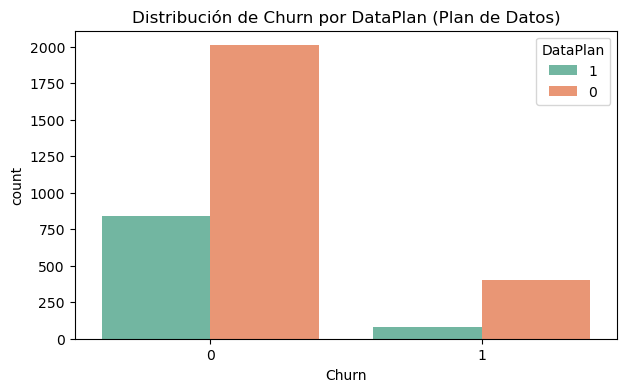

In [319]:
df2['DataPlan'] = df2['DataPlan'].astype(str)

plt.figure(figsize=(7, 4))  # Ajustar el tamaño de la figura
sns.countplot(x='Churn', hue='DataPlan', data=df2, palette='Set2')
plt.title('Distribución de Churn por DataPlan (Plan de Datos)')
plt.show()

- Podemos ver que la mayoría de clientes que no han cancelado el servicio no cuentan con un plan de datos (Churn = 0).
- Por otro lado, la mayoría de clientes que no han renovado el servicio no tenían tampoco plan de datos (Churn = 1).

Lo cual indica, que los planes de datos no son muy adquiridos por los clientes actuales y por los que dejaron de ser clientes.

Por otro lado, indica que posiblemente algo está sucediendo para que no adquieran los planes de datos y que posiblemente sea una buena oportunidad en la cual la empresa se puede enfocar para lograr mayores ingresos.

#### Veamos ahora el nivel de asociación entre las variables númericas

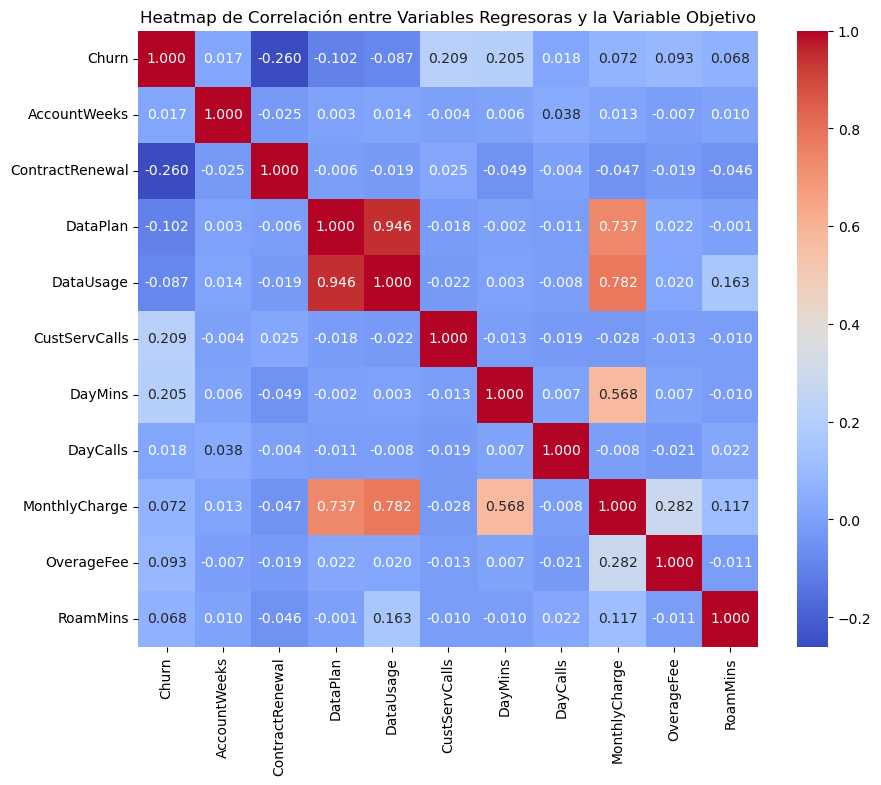

In [323]:
# Seleccionamos variables númericas
# Por lo cual, seleccionamos solamente las columnas float e int

# No descartamos la variable objetivo, con la finalidad de poder ver la asociacion entre las variables regresoras y la variable objetivo
#numeric_df = df.select_dtypes(include=[float, int]).drop(columns=['Churn'])

numeric_df = df.select_dtypes(include=[float, int])

# Calculamos la matriz de correlación
correlation_matrix = numeric_df.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".3f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras y la Variable Objetivo")
plt.show()

##### Otra forma de realizarlo

In [325]:
# Análisis de correlaciones
corr = df.corr()
corr.style.background_gradient(cmap='coolwarm')

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
Churn,1.000000,0.016541,-0.259852,-0.102148,-0.087195,0.208750,0.205151,0.018459,0.072313,0.092812,0.068239
AccountWeeks,0.016541,1.000000,-0.024735,0.002918,0.014391,-0.003796,0.006216,0.038470,0.012581,-0.006749,0.009514
ContractRenewal,-0.259852,-0.024735,1.000000,-0.006006,-0.019223,0.024522,-0.049396,-0.003755,-0.047291,-0.019105,-0.045871
DataPlan,-0.102148,0.002918,-0.006006,1.000000,0.945982,-0.017824,-0.001684,-0.011086,0.737490,0.021526,-0.001318
DataUsage,-0.087195,0.014391,-0.019223,0.945982,1.000000,-0.021723,0.003176,-0.007962,0.781660,0.019637,0.162746
CustServCalls,0.208750,-0.003796,0.024522,-0.017824,-0.021723,1.000000,-0.013423,-0.018942,-0.028017,-0.012964,-0.009640
DayMins,0.205151,0.006216,-0.049396,-0.001684,0.003176,-0.013423,1.000000,0.006750,0.567968,0.007038,-0.010155
DayCalls,0.018459,0.038470,-0.003755,-0.011086,-0.007962,-0.018942,0.006750,1.000000,-0.007963,-0.021449,0.021565
MonthlyCharge,0.072313,0.012581,-0.047291,0.737490,0.781660,-0.028017,0.567968,-0.007963,1.000000,0.281766,0.117433
OverageFee,0.092812,-0.006749,-0.019105,0.021526,0.019637,-0.012964,0.007038,-0.021449,0.281766,1.000000,-0.011023


Podemos ver en el gráfico que existen varias variables independientes que se correlacionan significativamente con la variable objetivo 'Churn', las cuales son las siguientes:
- ContractRenewal
- CustServCalls
- DayMins

Por otro lado, podemos ver en el grafico que existen varias variables independientes que se correlacionan significativamente:
- DataUsage con DataPlan
- MonthlyCharge con DataPlan, DataUsage y Daymins.

#### Pregunta 2

**2**. Desarrolla un modelo de árbol de decisión sin modificar sus hiper parámetros y despliega sus métricas de desempeño. Luego, mejora este modelo de forma de evitar el overfitting usando búsqueda por grilla con 5 kfold:
- max_depth: [5, 10, 15, 20, 25]
- min_samples_split: [0.01, 0.02, 0.03, 0.04]

Da a conocer los mejores hiper parámetros encontrados y el desempeño del modelo, tanto en los datos de entrenamiento como en los de test.

In [327]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [329]:
# Separamos el conjunto de variables independientes y dependientes (objetivo)

X = df.loc[:, df.columns != 'Churn']
y = df['Churn']

##### Modelo de árbol de decisión sin búsqueda de grilla

In [332]:
# Importamos DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier

# Separamos el conjunto de entrenamiento y de test
X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1234)

# Instanciamos DecisionTreeClassifier()
tree_cl = DecisionTreeClassifier()

# Entrenamos el modelo
tree_cl.fit(X_train, y_train)

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_train = tree_cl.predict(X_train)

# Estimamos las predicciones con el conjunto de test
yhat_test = tree_cl.predict(x_test)

##### Evaluamos el rendimiento del modelo y la clasificacion del conjunto de datos de entrenamiento

In [335]:
# Evaluamos el rendimiento del modelo con los datos de train
print('Accuracy: ', accuracy_score(y_train, yhat_train))
print('F1 Score: ', f1_score(y_train, yhat_train))

Accuracy:  1.0
F1 Score:  1.0


In [337]:
# Informe detallado de la clasificacion de los datos de train
print('\nInforme de clasificacion:')
print(classification_report(y_train, yhat_train))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2002
           1       1.00      1.00      1.00       331

    accuracy                           1.00      2333
   macro avg       1.00      1.00      1.00      2333
weighted avg       1.00      1.00      1.00      2333



##### Evaluamos el rendimiento del modelo y la clasificacion del conjunto de datos de test

In [340]:
# Evaluamos el rendimiento del modelo con los datos de test
print('Accuracy: ', accuracy_score(y_test, yhat_test))
print('F1 Score: ', f1_score(y_test, yhat_test))

Accuracy:  0.883
F1 Score:  0.6486486486486487


In [342]:
# Informe detallado de la clasificacion de los datos de test
print('\nInforme de clasificacion:')
print(classification_report(y_test, yhat_test))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.91      0.93       848
           1       0.60      0.71      0.65       152

    accuracy                           0.88      1000
   macro avg       0.77      0.81      0.79      1000
weighted avg       0.89      0.88      0.89      1000



##### Modelo de árbol de decisión con búsqueda de grilla

Procedemos ahora a mejorar el modelo con la finalidad de evitar el overfitting usando búsqueda por grilla con 5 kfold:
- max_depth: [5, 10, 15, 20, 25]
- min_samples_split: [0.01, 0.02, 0.03, 0.04]

In [346]:
grid_search = GridSearchCV(tree_cl,
                           {'max_depth': [5, 10, 15, 20, 25],
                            'min_samples_split': [0.01, 0.02, 0.03, 0.04]}, 
                           n_jobs=10, 
                           cv = 5)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=10,
             param_grid={'max_depth': [5, 10, 15, 20, 25],
                         'min_samples_split': [0.01, 0.02, 0.03, 0.04]})

In [348]:
grid_search.best_estimator_

DecisionTreeClassifier(max_depth=10, min_samples_split=0.02)

##### Mostramos la combinación óptima de hiperparámetros encontrados

In [351]:
print("Hiperparámetros óptimos:")
print(grid_search.best_params_)

Hiperparámetros óptimos:
{'max_depth': 10, 'min_samples_split': 0.02}


##### Desempeño del modelo en los datos de entrenamiento

In [353]:
# Desempeño del modelo en los datos de entrenamiento

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_train = grid_search.predict(X_train)

confusion_matrix(yhat_train, y_train)

array([[1964,  110],
       [  38,  221]], dtype=int64)

In [355]:
# Evaluamos el rendimiento del modelo en los datos de train
print('Accuracy: ', accuracy_score(y_train, yhat_train))
print('F1 Score: ', f1_score(y_train, yhat_train))

Accuracy:  0.9365623660522931
F1 Score:  0.7491525423728813


In [357]:
# Informe detallado de la clasificacion de los datos de train
print('\nInforme de clasificacion:')
print(classification_report(y_train, yhat_train))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96      2002
           1       0.85      0.67      0.75       331

    accuracy                           0.94      2333
   macro avg       0.90      0.82      0.86      2333
weighted avg       0.93      0.94      0.93      2333



##### Desempeño del modelo en los datos de test

In [359]:
# Desempeño del modelo en los datos de test

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_test = grid_search.predict(x_test)

confusion_matrix(yhat_test, y_test)

array([[827,  42],
       [ 21, 110]], dtype=int64)

In [361]:
# Evaluamos el rendimiento del modelo en los datos de test
print('Accuracy: ', accuracy_score(y_test, yhat_test))
print('F1 Score: ', f1_score(y_test, yhat_test))

Accuracy:  0.937
F1 Score:  0.7773851590106007


In [363]:
# Informe detallado de la clasificacion de los datos de test
print('\nInforme de clasificacion:')
print(classification_report(y_test, yhat_test))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       848
           1       0.84      0.72      0.78       152

    accuracy                           0.94      1000
   macro avg       0.90      0.85      0.87      1000
weighted avg       0.93      0.94      0.94      1000



Podemos ver que el desempeño del modelo del conjunto test usando una búsqueda con grilla con 5kfold, se ha podido evitar el sobre ajuste y, asimismo, el modelo ha logrado un muy desempeño mejor que el del entrenamiento y mejor que el modelo sin búsqueda de grilla

#### Pregunta 3

3. Balancea las clases usando SMOTE para el conjunto de entrenamiento. Luego, aplica un modelo de Bagging con 200 estimadores y muestra las métricas sobre el conjunto de test.

##### Procedemos en primera instancia a balancear las clases usando SMOTE para el conjunto de entrenamiento

In [366]:
# Procedemos a ver el conjunto de entrenamineto de y para ver las diferencias de clases.

y_train.value_counts()

Churn
0    2002
1     331
Name: count, dtype: int64

Si vemos tenemos una mayor proporcion de datos 0, que los de 1. Por lo cual, usaremos SMOTE para equilibrar los datos.

##### Aplicación de Smote

In [368]:
# Aplicamos SMOTE para balancear las clases en el conjunto de entrenamiento

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 1234)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Vemos la cantidad de clases despues de aplicar SMOTE
print(f"Distribución de clases antes de SMOTE: {y_train.value_counts()}\n")
print(f"Distribución de clases después de SMOTE: {y_train_smote.value_counts()}")

Distribución de clases antes de SMOTE: Churn
0    2002
1     331
Name: count, dtype: int64

Distribución de clases después de SMOTE: Churn
0    2002
1    2002
Name: count, dtype: int64


C:\Users\josek\anaconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


##### Procedemos ahora a aplicar un modelo Bagging con 200 estimadores

In [370]:
# Importamos la libreria BaggingClassifier

from sklearn.ensemble import BaggingClassifier

In [372]:
# Entrenar un modelo de Bagging con 200 estimadores (usando árboles de decisión como base)

# Instanciamos DecisionTreeClassifier()
tree_cl = DecisionTreeClassifier()

# Procedemos a hacer el modelo BaggingClassifier con 200 estimadores
bagging_cl = BaggingClassifier(estimator=tree_cl, n_estimators=200, random_state=1234)

# Procedemos a entrenar el modelo con el conjunto de entrenamiento balanceado
bagging_cl.fit(X_train_smote, y_train_smote)

# Prediccion para conjunto de test
yhat_test = bagging_cl.predict(x_test)

##### Mostramos las métricas sobre el conjunto de test

In [374]:
# Mostrar las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[790  58]
 [ 25 127]] 

Accuracy: 0.9170
F1 Score: 0.7537


In [376]:
print("\nReporte de clasificación:")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       848
           1       0.69      0.84      0.75       152

    accuracy                           0.92      1000
   macro avg       0.83      0.88      0.85      1000
weighted avg       0.93      0.92      0.92      1000



Podemos ver que el modelo Bagging ha tenido un buen desempeño, sin embargo, el modelo visto previamente de la **Pregunta 2**, el cual utiliza el conjunto test usando grilla con 5 kfold lo supera por un poco en cuanto a sus métricas.

#### Pregunta 4

4.	Implementa un modelo de Bagging usando modelos heterogéneos con los siguientes estimadores: Regresión Logística, Árbol de decisión, y dos SVM de clasificación con kernel ‘rbf’ y ‘sigmoid’. Para ello considera 200 muestras bootstrap (T). 

Debes calibrar la importancia de los modelos, repitiendo el modelo que sea más importante en la lista de modelos a entrenar. Considera que un mejor modelo es aquel con mejor f1-score. Muestra las métricas del modelo final aplicado al conjunto de test. (Para realizar esta tarea utiliza la función bagging_het que se encuentra en el archivo util_bagging.p
.py)T).t.

In [448]:
# Importamos la funcion

from util_bagging import bagging_het

Para este caso vamos a utilizar las muestras balanceadas con smote

In [465]:
estimators = [
    LogisticRegression(random_state=42, max_iter=400), # se esta colocando un max_iter = 400 para que pueda converger
    DecisionTreeClassifier(random_state=42),
    SVC(probability=True, random_state=42, kernel='rbf'),
    SVC(probability=True, random_state=42, kernel='sigmoid')  
]

f1_scores = []

for estimator in estimators:
    estimator.fit(X_train_smote, y_train_smote)
    y_pred = estimator.predict(x_test)  
    score = f1_score(y_test, y_pred)  
    f1_scores.append(score)

C:\Users\josek\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [467]:
for i, score in enumerate(f1_scores):
    print(f"F1-score por modelo {i} ({type(estimators[i]).__name__}): {score}")

F1-score por modelo 0 (LogisticRegression): 0.5069767441860465
F1-score por modelo 1 (DecisionTreeClassifier): 0.6542553191489362
F1-score por modelo 2 (SVC): 0.40789473684210525
F1-score por modelo 3 (SVC): 0.1994535519125683


##### En este caso el que presenta mejor F1-score es el modelo DecisionTreeClassifier con 0.654

In [475]:
# calculamos el indice del mejor modelo, que en este caso es el modelo 1
best_model_index = np.argmax(f1_scores)

In [477]:
# creamos una copia de los estimadores
estimators_rep = estimators[:]

# el mejor modelo lo colamos en la variable best_model
best_model = estimators[best_model_index]

# añadimos 2 instancias del mejor modelo a la lista estimators_rep, debido a que al ser mejor modelo queremos favorecerlo y que tenga más peso.
estimators_rep.extend([best_model] * 2) # se repite el mejor modelo

In [487]:
estimators_rep

[LogisticRegression(max_iter=400, random_state=42),
 DecisionTreeClassifier(random_state=42),
 SVC(probability=True, random_state=42),
 SVC(kernel='sigmoid', probability=True, random_state=42),
 DecisionTreeClassifier(random_state=42),
 DecisionTreeClassifier(random_state=42)]

In [479]:
# utilizamos la funcion bagging_het
T= 200
trained_models, yhat_test, yhat_out, idx_oob = bagging_het(X_train_smote, y_train_smote, T, estimators_rep, x_test)

C:\Users\josek\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\josek\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

##### Mostramos las métricas del modelo final aplicado al conjunto de test

In [483]:
# Calculamos y mostramos la métrica exactitud (accuracy)
accuracy = accuracy_score(y_test, yhat_out)
print("Accuracy:", accuracy)

# Calculamos y mostramos el F1-score
f1 = f1_score(y_test, yhat_out)
print("F1 Score:", f1)

# Mostramos el reporte de clasificación (precisión, recall y F1-score por clase)
print("Classification Report:")
print(classification_report(y_test, yhat_out))

# Mostramos la matriz de confusión
print("Confusion Matrix:")
print(confusion_matrix(y_test, yhat_out))

Accuracy: 0.911
F1 Score: 0.7420289855072464
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.95       848
           1       0.66      0.84      0.74       152

    accuracy                           0.91      1000
   macro avg       0.82      0.88      0.84      1000
weighted avg       0.92      0.91      0.92      1000

Confusion Matrix:
[[783  65]
 [ 24 128]]


Como vemos el modelo del esamblado bagging es muy bueno al tener un accuracy de 0.911 y f1 score de 0.74.

#### Pregunta 5

5.	Implementa un modelo de ensamble Random Forest usando como hiper parámetro n_estimators = 45. El modelo debe usar muestra OOB para estimar su ajuste ACCURACY, y debe mostrar las cuatro características más importantes junto con las métricas de desempeño en el conjunto de test.

In [379]:
# Configuramos el modelo Random Forest con n_estimators=45 y OOB

rf_clf = RandomForestClassifier(n_estimators=45, oob_score=True, random_state=1234)

# Procedemos a entrenar el modelo con el conjunto de entrenamiento
rf_clf.fit(X_train, y_train)

# prediccion para el conjunto de test
yhat_test = rf_clf.predict(x_test)

In [381]:
# Estimación de r^2 con datos OOB
rf_clf.oob_score_

0.9207029575653665

##### Mostramos las métricas de desempeño en el conjunto de test

In [383]:
# Mostramos las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[834  14]
 [ 37 115]] 

Accuracy: 0.9490
F1 Score: 0.8185


In [385]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       848
           1       0.89      0.76      0.82       152

    accuracy                           0.95      1000
   macro avg       0.92      0.87      0.89      1000
weighted avg       0.95      0.95      0.95      1000



Podemos ver que usando una tecnica de RandomForestClassifier, se pudo lograr un excelente desempeño al tener un Accuracy mayor a 0.9 y un F1 Score mayor a 0.8.

##### Desarrollo para mostrar las 4 caracteristicas más importantes del modelo

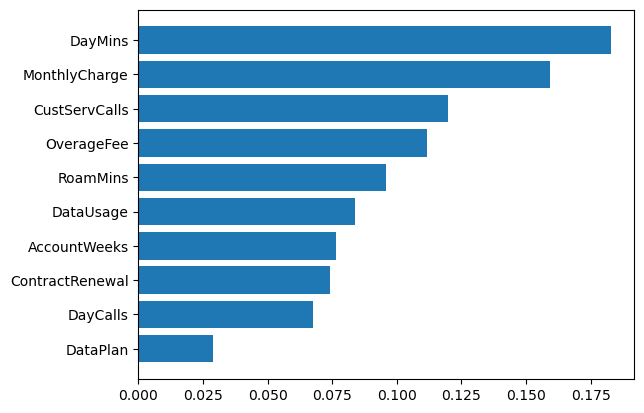

In [387]:
# visualizar importancia de los atributos del modelo

# Obtener los índices ordenados de las importancias
idx_sort = np.argsort(rf_clf.feature_importances_)

# Graficar las caracteristicas
plt.barh(y=rf_clf.feature_names_in_[idx_sort], width=rf_clf.feature_importances_[idx_sort]);

##### Mostramos solamente las 4 caracteristicas mas importantes

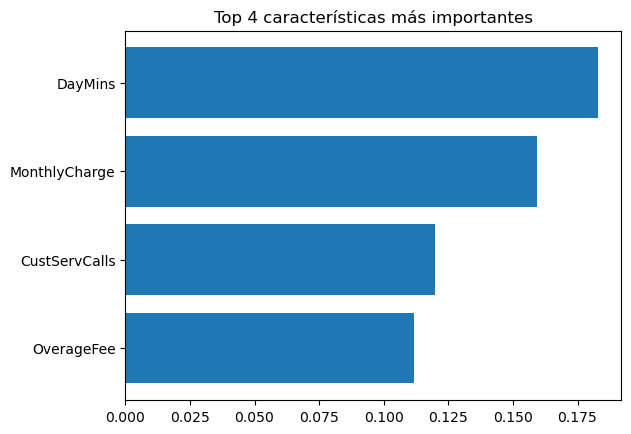

In [389]:
# Seleccionamos solamente las 4 características más importantes (las últimas 4 en idx_sort)
top_4_idx = idx_sort[-4:]

# Graficamos solamente las 4 características más importantes
plt.barh(y=rf_clf.feature_names_in_[top_4_idx], width=rf_clf.feature_importances_[top_4_idx])
plt.title('Top 4 características más importantes')
plt.show()

##### Otra manera de mostrar las 4 caracteristicas más importantes, pero de forma más detallada

In [392]:
# datos con la importancia de cada variable
importances = rf_clf.feature_importances_

# nombre de las variables
feature_names = X.columns

In [394]:
# Generamos un DataFrame
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [396]:
importance_df.head()

,Feature,Importance
5,DayMins,0.182820
7,MonthlyCharge,0.159247
4,CustServCalls,0.119978
8,OverageFee,0.111726
9,RoamMins,0.095713


In [398]:
# Mostramos las 4 características más importantes
print("\nLas 4 características más importantes:\n")
importance_df.head(4)


Las 4 características más importantes:



,Feature,Importance
5,DayMins,0.182820
7,MonthlyCharge,0.159247
4,CustServCalls,0.119978
8,OverageFee,0.111726


Visualizamos las 4 caracteristicas mas importantes en grafico usando el DataFrame que hemos generado recientemente importance_df

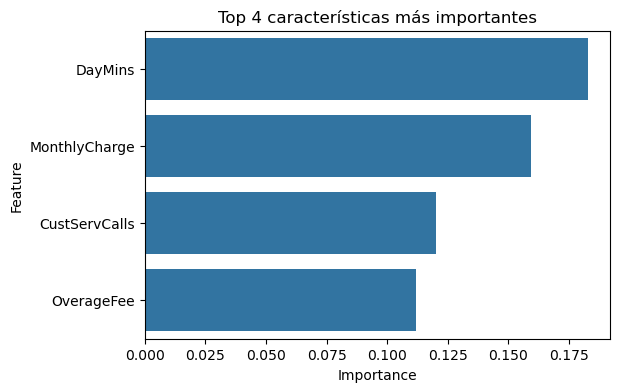

In [400]:
# Usamos el DataFrame importance_df

plt.figure(figsize=(6, 4))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(4))
plt.title('Top 4 características más importantes')
plt.show()

##### Pregunta 6

6.	Realiza una búsqueda de grilla para un modelo Random Forest para los siguientes rangos de valores para sus hiper parámetros:
    - n_estimators: 50 - 200 con paso de 10 completando 15 valores
    - max_features: [‘sqrt’, ‘log2’, None]



Muestra los mejores hiper parámetros encontrados, la estimación de desempeño en los datos OOB, y despliega los cuatro atributos más importantes. ¿Tienen sentido estos? Analiza además las métricas de desempeño, ROC y AUC.

In [402]:
param_grid = {
    'n_estimators': np.arange(50, 201, 10)[:15],
    'max_features': ['sqrt', 'log2', None]
}

In [404]:
grid_model6 = GridSearchCV(
    RandomForestClassifier(oob_score=True, random_state=1234),
    param_grid=param_grid,
    n_jobs=-1
)

grid_model6.fit(X_train, y_train)

GridSearchCV(estimator=RandomForestClassifier(oob_score=True,
                                              random_state=1234),
             n_jobs=-1,
             param_grid={'max_features': ['sqrt', 'log2', None],
                         'n_estimators': array([ 50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170,
       180, 190])})

In [406]:
grid_model6.best_estimator_

RandomForestClassifier(n_estimators=130, oob_score=True, random_state=1234)

#### Mejores hiper parámetros encontrados

In [408]:
print('\n---')
print('Mejores valores de hiper parámetros encontrados:')
print(grid_model6.best_params_)
print('---\n')


---
Mejores valores de hiper parámetros encontrados:
{'max_features': 'sqrt', 'n_estimators': 130}
---



In [410]:
# obtenemos el mejor modelo
best_rf_clf_model = grid_model6.best_estimator_

# Realizar predicciones en el conjunto de prueba
yhat_test = best_rf_clf_model.predict(x_test)

##### Medición de r2 desde datos OOB

In [412]:
best_rf_clf_model.oob_score_

0.9241320188598371

##### Mostramos las métricas de desempeño en el conjunto de test

In [414]:
# Mostramos las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[838  10]
 [ 38 114]] 

Accuracy: 0.9520
F1 Score: 0.8261


In [416]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       848
           1       0.92      0.75      0.83       152

    accuracy                           0.95      1000
   macro avg       0.94      0.87      0.90      1000
weighted avg       0.95      0.95      0.95      1000



Podemos ver que tenemos un muy buen modelo de Random Forest al tener métricas con muy buen desempeño.

##### Desarrollo para mostrar los 4 atributos más importantes.

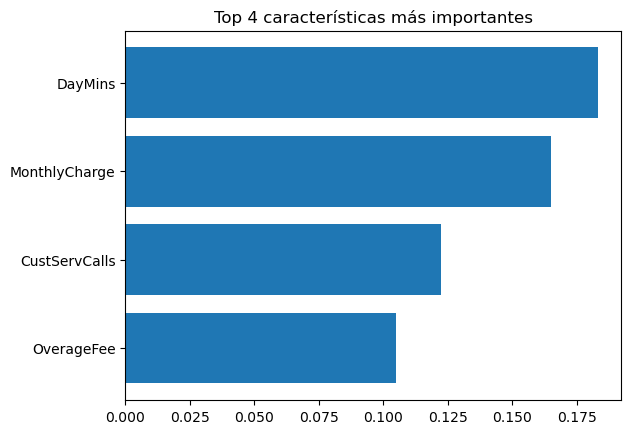

In [418]:
# Obtener los índices ordenados de las importancias
idx_sort = np.argsort(best_rf_clf_model.feature_importances_)

# Seleccionamos solamente las 4 características más importantes (las últimas 4 en idx_sort)
top_4_idx = idx_sort[-4:]

# Graficamos solamente las 4 características más importantes
plt.barh(y=best_rf_clf_model.feature_names_in_[top_4_idx], width=best_rf_clf_model.feature_importances_[top_4_idx])
plt.title('Top 4 características más importantes')
plt.show()

In [430]:
# Análisis de correlaciones
corr = df.corr()
corr.style.background_gradient(cmap='coolwarm')

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
Churn,1.000000,0.016541,-0.259852,-0.102148,-0.087195,0.208750,0.205151,0.018459,0.072313,0.092812,0.068239
AccountWeeks,0.016541,1.000000,-0.024735,0.002918,0.014391,-0.003796,0.006216,0.038470,0.012581,-0.006749,0.009514
ContractRenewal,-0.259852,-0.024735,1.000000,-0.006006,-0.019223,0.024522,-0.049396,-0.003755,-0.047291,-0.019105,-0.045871
DataPlan,-0.102148,0.002918,-0.006006,1.000000,0.945982,-0.017824,-0.001684,-0.011086,0.737490,0.021526,-0.001318
DataUsage,-0.087195,0.014391,-0.019223,0.945982,1.000000,-0.021723,0.003176,-0.007962,0.781660,0.019637,0.162746
CustServCalls,0.208750,-0.003796,0.024522,-0.017824,-0.021723,1.000000,-0.013423,-0.018942,-0.028017,-0.012964,-0.009640
DayMins,0.205151,0.006216,-0.049396,-0.001684,0.003176,-0.013423,1.000000,0.006750,0.567968,0.007038,-0.010155
DayCalls,0.018459,0.038470,-0.003755,-0.011086,-0.007962,-0.018942,0.006750,1.000000,-0.007963,-0.021449,0.021565
MonthlyCharge,0.072313,0.012581,-0.047291,0.737490,0.781660,-0.028017,0.567968,-0.007963,1.000000,0.281766,0.117433
OverageFee,0.092812,-0.006749,-0.019105,0.021526,0.019637,-0.012964,0.007038,-0.021449,0.281766,1.000000,-0.011023


##### Respecto a los 4 atributos
- DayMins
- MonthlyCharge
- CustServCalls
- OverageFee

Podemos indicar que estas características son las que más importa a un cliente para continuar el servicio. 

De hecho estás características al momento de hacer el heatmap, se mostraban cómo las importantes en especial CustServCalls y DayMins, las cuales influían en un 20% aproximadamente cada una de ellas en la variable objetivo Churn.

Por otro lado, podemos ver que la mayoría de sus clientes contratan el servicio de telefonía para realizar tareas básicas como las llamadas, que el servicio tenga un adecuado precio y que tengan una buena atención al cliente en caso de inconvenientes. Es por eso, que la mayoría de los clientes no estaban afiliados al plan de datos. Porque estos clientes buscan lo que anteriormente menciono y priorizan que sea un servicio confiable y económico, por eso se presentan estas 2 mismas variables MonthlyCharge y OverageFee. 

Lo más seguro es que sus clientes sean colaboradores de empresa y por eso no cuentan con un plan de datos.

##### Analisis de ROC y AUC

Predecimos las probabilidades para el conjunto de test (para clase 1)

In [422]:
# Para realizar la curva, necesitamos calcular las probabilidades de cada una de las observaciones.
# Por lo cual, predecimos las probabilidades para el conjunto de test (para la clase 1)
# Recordar que clase 1 viene a significar que el cliente ha cancelado el servicio.

yhat_roc = best_rf_clf_model.predict_proba(x_test)[:, 1]

Calculamos la curva ROC

In [424]:
# Falsos positivos -> false_positive
# Verdaderos positivos -> true_positive
# threshold -> umbral de decisión
false_positive, true_positive, threshold = roc_curve(y_test, yhat_roc)

Calculamos el AUC

In [426]:
auc = roc_auc_score(y_test, yhat_roc)
print(f"AUC: {auc:.3f}")

AUC: 0.929


El AUC al ser superior a 0.9, indica un buen desempeño.

Procedemos a graficar la curva ROC

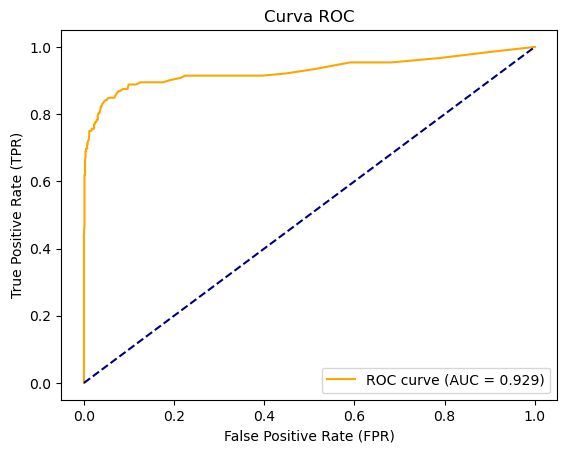

In [428]:
plt.figure()
plt.plot(false_positive, true_positive, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

##### Pregunta 7

7.	Usando el modelo Random Forest con sus hiper parámetros ajustados, muestre los 15 clientes que presentan la mayor propensión a renunciar.

##### Recordar lo siguiente sobre la variable objetivo

- Churn (Variable objetivo): valor 1 si el cliente canceló el servicio, 0 si no

##### Para resolver la pregunta 7 realizaremos 3 pasos con las siguientes secuencias: **a, b y c**

a. Obtener las probabilidades respecto al conjunto de prueba de que cada persona cancele el servicio de telefonía.

Por lo tanto, vamos estimar las probabilidades respecto a la clase 1 en Churn, debido a que me dará las probabilidades de cancelación de servicio de cada uno de los clientes.

In [434]:
# Recordar que ya se han calculado las probabilidades para el conjunto de test (para la clase 1), es decir, para los clientes
# que han cancelado el servicio

# Se hizo en el Analisis de ROC y AUC

# yhat_roc = best_rf_clf_model.predict_proba(x_test)[:, 1] - ya tenemos las probabilidades

b. Procedemos a extraer esas probabilidades, colocarlas en un DataFrame y ordenarlas de mayor a menor.

In [436]:
# Por lo cual extraemos las probabilidades de cancelación de servicio de cada uno de los clientes y lo colocamos en un DataFrame
# Asimismo, en el dataframe colocamos los valores reales de cancelación de servicio y_test.
df_probabilidad = pd.DataFrame({'Probabilidad_de_cancelacion_de_servicio': yhat_roc, 'Prueba_real': y_test})

# Procedemos a ordenar las probabilidades de haber cancelado el servicio de mayor a menor
df_probabilidad_ordenado = df_probabilidad.sort_values(by = 'Probabilidad_de_cancelacion_de_servicio', ascending = False)

c. Mostramos los 15 clientes que presentan la mayor propension a renunciar

In [438]:
df_top_15 = df_probabilidad_ordenado.head(15)

In [440]:
df_top_15

,Probabilidad_de_cancelacion_de_servicio,Prueba_real
3205,0.992308,1
2708,0.984615,1
2573,0.984615,1
3132,0.976923,1
2099,0.976923,1
2536,0.976923,1
2647,0.969231,1
3079,0.961538,1
21,0.961538,1
1405,0.946154,1


Estos son los clientes que son más propensos a cancelar el servicio de telefonía, podemos identificar a cada uno de los clientes por medio del índice del dataframe.